<a href="https://colab.research.google.com/github/MuskanMehta-2006/DDI_Prediction/blob/main/99_4_validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import gc
import random
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DRUG_DIR = "/content/drive/MyDrive/DRUG"

STRUCTURE_PATH = (
    "/content/drive/MyDrive/DRUG/Structures/"
    "drugbank_all_structure_links.csv/structure links.csv"
)

TARGET_PATH = (
    "/content/drive/MyDrive/DRUG/Drug_Target_Identifier/"
    "drugbank_all_target_polypeptide_ids.csv/all.csv"
)

ENZYME_PATH = (
    "/content/drive/MyDrive/DRUG/Drug_Enzyme_Identifier/"
    "drugbank_all_enzyme_polypeptide_ids.csv/all.csv"
)

TRANSPORTER_PATH = (
    "/content/drive/MyDrive/DRUG/Drug_Transporter_Identifier/"
    "drugbank_all_transporter_polypeptide_ids.csv/all.csv"
)

CARRIER_PATH = (
    "/content/drive/MyDrive/DRUG/Drug_Carrier_Identifier/"
    "drugbank_all_carrier_polypeptide_ids.csv/all.csv"
)

XML_PATH = (
    "/content/drive/MyDrive/DRUG/Full_Database/"
    "drugbank_all_full_database.xml/full database.xml"
)

print("Environment ready.")
print("DRUG folder:", os.path.exists(DRUG_DIR))
print("Structure file:", os.path.exists(STRUCTURE_PATH))
print("XML file:", os.path.exists(XML_PATH))
print("Seed:", SEED)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Environment ready.
DRUG folder: True
Structure file: True
XML file: True
Seed: 42


In [ ]:
# Check previously saved DDI artifacts from the original notebook
PROCESSED_DIR = "/content/drive/MyDrive/Explainable_DDI/data/processed"

print("Processed directory exists:", os.path.exists(PROCESSED_DIR))

if os.path.exists(PROCESSED_DIR):
    print("\nSaved artifacts:\n")

    for root, dirs, files in os.walk(PROCESSED_DIR):
        for f in sorted(files):
            path = os.path.join(root, f)
            size_mb = os.path.getsize(path) / (1024 ** 2)
            print(f"{size_mb:9.2f} MB  {path}")

Processed directory exists: True

Saved artifacts:

   152.71 MB  /content/drive/MyDrive/Explainable_DDI/data/processed/ddi_full.csv
    57.53 MB  /content/drive/MyDrive/Explainable_DDI/data/processed/ddi_positive.csv


In [ ]:
DDI_FULL_PATH = "/content/drive/MyDrive/Explainable_DDI/data/processed/ddi_full.csv"

ddi_full = pd.read_csv(DDI_FULL_PATH)

print("Shape:", ddi_full.shape)

print("\nColumns:")
print(ddi_full.columns.tolist())

print("\nLabel distribution:")
print(ddi_full["label"].value_counts())

print("\nMemory usage:")
print(round(ddi_full.memory_usage(deep=True).sum() / (1024**2), 2), "MB")

print("\nFirst 5 rows:")
display(ddi_full.head())

Shape: (2668200, 5)

Columns:
['drug_a', 'drug_b', 'drug_a_name', 'drug_b_name', 'label']

Label distribution:
label
0    1334100
1    1334100
Name: count, dtype: int64

Memory usage:
655.97 MB

First 5 rows:


,drug_a,drug_b,drug_a_name,drug_b_name,label
0,DB03872,DB04684,"2,3-Dideoxyfucose",Bis(6-aminohexyl)amine,0
1,DB05109,DB06290,Trabectedin,Simeprevir,1
2,DB01624,DB05235,Zuclopenthixol,NRP409,0
3,DB01559,DB06155,Clotiazepam,Rimonabant,1
4,DB00252,DB01103,Phenytoin,Quinacrine,1


In [ ]:
from sklearn.model_selection import train_test_split

# Recreate the exact split used in the original notebook
train_df, temp_df = train_test_split(
    ddi_full,
    test_size=0.20,
    stratify=ddi_full["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTrain labels:")
print(train_df["label"].value_counts())

print("\nValidation labels:")
print(val_df["label"].value_counts())

print("\nTest labels:")
print(test_df["label"].value_counts())

Train: (2134560, 5)
Validation: (266820, 5)
Test: (266820, 5)

Train labels:
label
1    1067280
0    1067280
Name: count, dtype: int64

Validation labels:
label
1    133410
0    133410
Name: count, dtype: int64

Test labels:
label
0    133410
1    133410
Name: count, dtype: int64


In [ ]:
# Free redundant large dataframe copies
del ddi_full
del temp_df
gc.collect()

# Names are not needed for model training
for df in [train_df, val_df, test_df]:
    df.drop(
        columns=["drug_a_name", "drug_b_name"],
        inplace=True
    )

# Keep only required columns and compact string storage
train_df = train_df[["drug_a", "drug_b", "label"]]
val_df = val_df[["drug_a", "drug_b", "label"]]
test_df = test_df[["drug_a", "drug_b", "label"]]

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nRAM after cleanup:")
import psutil
ram = psutil.virtual_memory()
print(f"Used: {ram.used / (1024**3):.2f} GB")
print(f"Available: {ram.available / (1024**3):.2f} GB")

Train: (2134560, 3)
Validation: (266820, 3)
Test: (266820, 3)

RAM after cleanup:
Used: 4.11 GB
Available: 8.23 GB


In [ ]:
# ============================================================
# BUILD TRAINING POSITIVE DDI GRAPH — RAM EFFICIENT
# ============================================================

from collections import defaultdict

# Only positive training pairs
train_pos = train_df.loc[
    train_df["label"].eq(1),
    ["drug_a", "drug_b"]
]

# Unique drug IDs appearing in training positives
graph_drugs = pd.unique(
    train_pos[["drug_a", "drug_b"]].values.ravel()
)

# Compact integer ID for every drug
drug_to_idx = {
    drug: i for i, drug in enumerate(graph_drugs)
}

# Convert edges to compact int32 arrays
edge_a = train_pos["drug_a"].map(drug_to_idx).to_numpy(dtype=np.int32)
edge_b = train_pos["drug_b"].map(drug_to_idx).to_numpy(dtype=np.int32)

# Degree of each drug
degree = np.bincount(
    np.concatenate([edge_a, edge_b]),
    minlength=len(graph_drugs)
)

print("Training positive pairs:", len(train_pos))
print("Graph nodes:", len(graph_drugs))
print("Graph edges:", len(edge_a))
print("Average degree:", round(degree.mean(), 2))
print("Maximum degree:", degree.max())

print("\nGraph arrays:")
print("edge_a:", edge_a.shape, edge_a.dtype)
print("edge_b:", edge_b.shape, edge_b.dtype)
print("degree:", degree.shape, degree.dtype)

# Release temporary dataframe
del train_pos
gc.collect()

ram = psutil.virtual_memory()
print(f"\nAvailable RAM: {ram.available / (1024**3):.2f} GB")

Training positive pairs: 1067280
Graph nodes: 4250
Graph edges: 1067280
Average degree: 502.25
Maximum degree: 1994

Graph arrays:
edge_a: (1067280,) int32
edge_b: (1067280,) int32
degree: (4250,) int64

Available RAM: 8.23 GB


In [ ]:
!pip install gensim

In [ ]:
from gensim.models import Word2Vec

# Build compact adjacency lists
adj = [[] for _ in range(len(graph_drugs))]

for a, b in zip(edge_a, edge_b):
    adj[a].append(int(b))
    adj[b].append(int(a))

print("Adjacency built.")

class RandomWalkCorpus:
    def __init__(self, adjacency, num_walks=10, walk_length=25, seed=42):
        self.adjacency = adjacency
        self.num_walks = num_walks
        self.walk_length = walk_length
        self.seed = seed

    def __iter__(self):
        rng = random.Random(self.seed)

        nodes = list(range(len(self.adjacency)))

        for _ in range(self.num_walks):
            rng.shuffle(nodes)

            for start in nodes:
                walk = [str(start)]
                current = start

                for _ in range(self.walk_length - 1):
                    neighbors = self.adjacency[current]

                    if not neighbors:
                        break

                    current = rng.choice(neighbors)
                    walk.append(str(current))

                yield walk


walk_corpus = RandomWalkCorpus(
    adj,
    num_walks=10,
    walk_length=25,
    seed=SEED
)

print("Training Word2Vec...")

graph_w2v = Word2Vec(
    sentences=walk_corpus,
    vector_size=96,
    window=7,
    min_count=1,
    sg=1,
    workers=2,
    epochs=10,
    seed=SEED
)

print("\nEmbedding training complete.")
print("Vocabulary:", len(graph_w2v.wv))
print("Embedding dimension:", graph_w2v.vector_size)

ram = psutil.virtual_memory()
print(f"Available RAM: {ram.available / (1024**3):.2f} GB")

Adjacency built.
Training Word2Vec...

Embedding training complete.
Vocabulary: 4250
Embedding dimension: 96
Available RAM: 8.19 GB


In [ ]:
import numpy as np
import gc

# Embedding matrix: (4250, 96)
graph_embeddings = np.asarray(
    [graph_w2v.wv[str(i)] for i in range(len(graph_drugs))],
    dtype=np.float32
)

print("Embedding matrix:", graph_embeddings.shape)
print("Embedding dtype:", graph_embeddings.dtype)

# Map graph drug IDs to integer indices
def map_graph_pairs(df):
    a = df["drug_a"].map(drug_to_idx).to_numpy()
    b = df["drug_b"].map(drug_to_idx).to_numpy()

    valid = (~pd.isna(a)) & (~pd.isna(b))

    a = np.where(valid, a, -1).astype(np.int32)
    b = np.where(valid, b, -1).astype(np.int32)

    return a, b, valid


# Generate 10 compact graph-pair features in batches
def make_graph_features(df, batch_size=100_000):

    n = len(df)
    features = np.zeros((n, 10), dtype=np.float32)

    a_idx, b_idx, valid = map_graph_pairs(df)

    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)

        a = a_idx[start:end]
        b = b_idx[start:end]
        mask = valid[start:end]

        if not np.any(mask):
            continue

        ea = graph_embeddings[a[mask]]
        eb = graph_embeddings[b[mask]]

        diff = ea - eb
        abs_diff = np.abs(diff)
        product = ea * eb

        norm_a = np.linalg.norm(ea, axis=1)
        norm_b = np.linalg.norm(eb, axis=1)

        dot = np.sum(product, axis=1)

        cosine = dot / (
            norm_a * norm_b + 1e-8
        )

        euclidean = np.linalg.norm(diff, axis=1)

        features[start:end][mask, 0] = cosine
        features[start:end][mask, 1] = dot
        features[start:end][mask, 2] = euclidean
        features[start:end][mask, 3] = np.mean(abs_diff, axis=1)
        features[start:end][mask, 4] = np.max(abs_diff, axis=1)
        features[start:end][mask, 5] = np.mean(product, axis=1)
        features[start:end][mask, 6] = np.max(product, axis=1)
        features[start:end][mask, 7] = np.mean((ea + eb) / 2, axis=1)
        features[start:end][mask, 8] = np.std((ea + eb) / 2, axis=1)
        features[start:end][mask, 9] = np.abs(norm_a - norm_b)

    return features


print("Graph feature generator ready.")
print("Available RAM:", f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB")

Embedding matrix: (4250, 96)
Embedding dtype: float32
Graph feature generator ready.
Available RAM: 8.19 GB


In [ ]:
print("Generating training graph features...")

train_graph_features = make_graph_features(
    train_df,
    batch_size=100_000
)

print("Train graph features:", train_graph_features.shape)
print("Dtype:", train_graph_features.dtype)
print("Available RAM:", f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB")

Generating training graph features...
Train graph features: (2134560, 10)
Dtype: float32
Available RAM: 8.19 GB


In [ ]:
print("Generating validation graph features...")

val_graph_features = make_graph_features(
    val_df,
    batch_size=100_000
)

print("Validation graph features:", val_graph_features.shape)

print("\nGenerating test graph features...")

test_graph_features = make_graph_features(
    test_df,
    batch_size=100_000
)

print("Test graph features:", test_graph_features.shape)

print(
    "\nAvailable RAM:",
    f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB"
)

Generating validation graph features...
Validation graph features: (266820, 10)

Generating test graph features...
Test graph features: (266820, 10)

Available RAM: 8.19 GB


In [ ]:
# Degree lookup as float32
degree_f32 = degree.astype(np.float32)

def make_degree_features(df):
    a_idx, b_idx, valid = map_graph_pairs(df)

    out = np.zeros((len(df), 4), dtype=np.float32)

    mask = valid

    if np.any(mask):
        da = degree_f32[a_idx[mask]]
        db = degree_f32[b_idx[mask]]

        out[mask, 0] = da
        out[mask, 1] = db
        out[mask, 2] = np.abs(da - db)
        out[mask, 3] = np.minimum(da, db) / (
            np.maximum(da, db) + 1e-6
        )

    return out


train_degree_features = make_degree_features(train_df)
val_degree_features = make_degree_features(val_df)
test_degree_features = make_degree_features(test_df)

print("Train degree features:", train_degree_features.shape)
print("Validation degree features:", val_degree_features.shape)
print("Test degree features:", test_degree_features.shape)

print("\nSample:")
print(train_degree_features[:5])

print(
    "\nAvailable RAM:",
    f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB"
)

Train degree features: (2134560, 4)
Validation degree features: (266820, 4)
Test degree features: (266820, 4)

Sample:
[[1.012000e+03 4.800000e+02 5.320000e+02 4.743083e-01]
 [8.730000e+02 7.190000e+02 1.540000e+02 8.235968e-01]
 [0.000000e+00 0.000000e+00 0.000000e+00 0.000000e+00]
 [0.000000e+00 0.000000e+00 0.000000e+00 0.000000e+00]
 [8.250000e+02 1.880000e+02 6.370000e+02 2.278788e-01]]

Available RAM: 8.19 GB


In [ ]:
train_graph_features = np.concatenate(
    [train_graph_features, train_degree_features],
    axis=1
)

val_graph_features = np.concatenate(
    [val_graph_features, val_degree_features],
    axis=1
)

test_graph_features = np.concatenate(
    [test_graph_features, test_degree_features],
    axis=1
)

print("Train graph features:", train_graph_features.shape)
print("Validation graph features:", val_graph_features.shape)
print("Test graph features:", test_graph_features.shape)

print(
    "\nAvailable RAM:",
    f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB"
)

Train graph features: (2134560, 14)
Validation graph features: (266820, 14)
Test graph features: (266820, 14)

Available RAM: 8.19 GB


In [ ]:
feature_names = [
    "cosine",
    "dot",
    "euclidean",
    "mean_abs_diff",
    "max_abs_diff",
    "mean_product",
    "max_product",
    "embedding_mean",
    "embedding_std",
    "norm_difference",
    "degree_a",
    "degree_b",
    "degree_difference",
    "degree_ratio"
]

graph_signal = pd.DataFrame({
    "feature": feature_names,
    "positive_mean": train_graph_features[train_df["label"].to_numpy() == 1].mean(axis=0),
    "negative_mean": train_graph_features[train_df["label"].to_numpy() == 0].mean(axis=0)
})

graph_signal["abs_difference"] = (
    graph_signal["positive_mean"] -
    graph_signal["negative_mean"]
).abs()

print(graph_signal.to_string(index=False))

del graph_signal
gc.collect()

print(
    "\nAvailable RAM:",
    f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB"
)

          feature  positive_mean  negative_mean  abs_difference
           cosine       0.347234       0.018083        0.329150
              dot       1.877479       0.094103        1.783376
        euclidean       2.574433       0.250906        2.323528
    mean_abs_diff       0.210200       0.020506        0.189695
     max_abs_diff       0.719524       0.069662        0.649862
     mean_product       0.019557       0.000980        0.018577
      max_product       0.267893       0.020676        0.247217
   embedding_mean       0.000452      -0.000260        0.000713
    embedding_std       0.190438       0.015720        0.174718
  norm_difference       0.205962       0.026673        0.179289
         degree_a     926.513245      46.276951      880.236267
         degree_b     780.438049      33.076565      747.361511
degree_difference     419.341797      43.559155      375.782654
     degree_ratio       0.627340       0.025902        0.601437

Available RAM: 8.19 GB


In [ ]:
!pip install rdkit

In [ ]:
structure_check = pd.read_csv(
    STRUCTURE_PATH,
    nrows=3
)

print("Columns:")
print(structure_check.columns.tolist())

print("\nSample:")
print(structure_check.head(3).to_string())

del structure_check
gc.collect()

Columns:
['DrugBank ID', 'Name', 'CAS Number', 'Drug Groups', 'InChIKey', 'InChI', 'SMILES', 'Formula', 'KEGG Compound ID', 'KEGG Drug ID', 'PubChem Compound ID', 'PubChem Substance ID', 'ChEBI ID', 'ChEMBL ID', 'HET ID', 'ChemSpider ID', 'BindingDB ID']

Sample:
  DrugBank ID         Name   CAS Number                Drug Groups                     InChIKey                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 

30

In [ ]:
from rdkit import Chem
from rdkit.Chem import Descriptors, rdFingerprintGenerator
import numpy as np
import pandas as pd
import gc

FP_BITS = 1024
FP_RADIUS = 2
DESC_COUNT = 10

morgan_gen = rdFingerprintGenerator.GetMorganGenerator(
    radius=FP_RADIUS,
    fpSize=FP_BITS
)

structure_df = pd.read_csv(
    STRUCTURE_PATH,
    usecols=["DrugBank ID", "SMILES"]
)

structure_df = structure_df.drop_duplicates("DrugBank ID")
structure_df = structure_df.set_index("DrugBank ID")

descriptor_functions = [
    Descriptors.MolWt,
    Descriptors.MolLogP,
    Descriptors.TPSA,
    Descriptors.NumHDonors,
    Descriptors.NumHAcceptors,
    Descriptors.RingCount,
    Descriptors.FractionCSP3,
    Descriptors.BertzCT,
    Descriptors.LabuteASA,
    Descriptors.HeavyAtomCount
]

molecular_features = np.zeros(
    (len(graph_drugs), FP_BITS + DESC_COUNT),
    dtype=np.float32
)

missing = 0
invalid = 0

for i, drug in enumerate(graph_drugs):
    smiles = structure_df["SMILES"].get(drug, None)

    if pd.isna(smiles) or not isinstance(smiles, str) or not smiles.strip():
        missing += 1
        continue

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        invalid += 1
        continue

    fp = morgan_gen.GetFingerprint(mol)

    molecular_features[i, :FP_BITS] = np.asarray(
        fp, dtype=np.float32
    )

    desc = np.asarray(
        [fn(mol) for fn in descriptor_functions],
        dtype=np.float64
    )

    desc = np.nan_to_num(
        desc,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )

    molecular_features[i, FP_BITS:] = desc.astype(np.float32)

print("Molecular feature matrix:", molecular_features.shape)
print("Expected shape:", (len(graph_drugs), 1034))
print("Missing SMILES:", missing)
print("Invalid SMILES:", invalid)
print("Feature dtype:", molecular_features.dtype)
print(
    "Feature memory:",
    f"{molecular_features.nbytes / (1024**2):.2f} MB"
)
print(
    "Available RAM:",
    f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB"
)


[17:51:05] SMILES Parse Error: syntax error while parsing: OC1=CC=CC(=C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C1=CC(O)=CC=C1)\C1=CC(O)=CC=C1
[17:51:05] SMILES Parse Error: check for mistakes around position 76:
[17:51:05] C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C
[17:51:05] ~~~~~~~~~~~~~~~~~~~~^
[17:51:05] SMILES Parse Error: extra open parentheses while parsing: OC1=CC=CC(=C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C1=CC(O)=CC=C1)\C1=CC(O)=CC=C1
[17:51:05] SMILES Parse Error: check for mistakes around position 32:
[17:51:05] C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2
[17:51:05] ~~~~~~~~~~~~~~~~~~~~^
[17:51:05] SMILES Parse Error: extra open parentheses while parsing: OC1=CC=CC(=C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C1=CC(O)=CC=C1)\C1=CC(O)=CC=C1
[17:51:05] SMILES Parse Error: check for mistakes around position 49:
[17:51:05] )\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=

Molecular feature matrix: (4250, 1034)
Expected shape: (4250, 1034)
Missing SMILES: 725
Invalid SMILES: 1
Feature dtype: float32
Feature memory: 16.76 MB
Available RAM: 8.17 GB


In [ ]:
def make_molecular_pair_features(df, batch_size=100_000):

    n = len(df)

    # 10 compact pair features
    out = np.zeros((n, 10), dtype=np.float32)

    a_idx, b_idx, valid = map_graph_pairs(df)

    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)

        mask = valid[start:end]

        if not np.any(mask):
            continue

        ea = molecular_features[a_idx[start:end][mask]]
        eb = molecular_features[b_idx[start:end][mask]]

        # Fingerprint part
        fa = ea[:, :FP_BITS]
        fb = eb[:, :FP_BITS]

        intersection = np.sum(fa * fb, axis=1)
        union = np.sum(
            ((fa + fb) > 0).astype(np.float32),
            axis=1
        )

        bits_a = np.sum(fa, axis=1)
        bits_b = np.sum(fb, axis=1)

        tanimoto = intersection / (union + 1e-8)

        # Descriptor part
        da = ea[:, FP_BITS:]
        db = eb[:, FP_BITS:]

        desc_diff = np.abs(da - db)
        desc_mean = (da + db) / 2.0

        out[start:end][mask, 0] = tanimoto
        out[start:end][mask, 1] = intersection
        out[start:end][mask, 2] = union
        out[start:end][mask, 3] = bits_a
        out[start:end][mask, 4] = bits_b
        out[start:end][mask, 5] = bits_a / (bits_b + 1e-8)
        out[start:end][mask, 6] = np.mean(desc_diff, axis=1)
        out[start:end][mask, 7] = np.max(desc_diff, axis=1)
        out[start:end][mask, 8] = np.mean(desc_mean, axis=1)
        out[start:end][mask, 9] = np.std(desc_mean, axis=1)

    return out


print("Generating training molecular pair features...")

train_mol_features = make_molecular_pair_features(
    train_df,
    batch_size=100_000
)

print("Train molecular features:", train_mol_features.shape)
print("Dtype:", train_mol_features.dtype)

print(
    "Available RAM:",
    f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB"
)

Generating training molecular pair features...
Train molecular features: (2134560, 10)
Dtype: float32
Available RAM: 10.74 GB


In [ ]:
print("Generating validation molecular pair features...")

val_mol_features = make_molecular_pair_features(
    val_df,
    batch_size=100_000
)

print("Generating test molecular pair features...")

test_mol_features = make_molecular_pair_features(
    test_df,
    batch_size=100_000
)

print("Validation molecular features:", val_mol_features.shape)
print("Test molecular features:", test_mol_features.shape)

print(
    "Available RAM:",
    f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB"
)

Generating validation molecular pair features...
Generating test molecular pair features...
Validation molecular features: (266820, 10)
Test molecular features: (266820, 10)
Available RAM: 10.83 GB


In [ ]:
feature_names = [
    "tanimoto",
    "intersection",
    "union",
    "bits_a",
    "bits_b",
    "bit_ratio",
    "mean_desc_diff",
    "max_desc_diff",
    "mean_desc",
    "std_desc"
]

signal_check = []

positive_mask = train_df["label"].to_numpy() == 1
negative_mask = ~positive_mask

for i, name in enumerate(feature_names):

    pos_mean = train_mol_features[positive_mask, i].mean()
    neg_mean = train_mol_features[negative_mask, i].mean()

    signal_check.append([
        name,
        pos_mean,
        neg_mean,
        abs(pos_mean - neg_mean)
    ])

signal_check_df = pd.DataFrame(
    signal_check,
    columns=[
        "feature",
        "positive_mean",
        "negative_mean",
        "abs_difference"
    ]
).sort_values(
    "abs_difference",
    ascending=False
)

print(signal_check_df.to_string(index=False))

       feature  positive_mean  negative_mean  abs_difference
     bit_ratio   2.868452e+08   1.426870e+07    2.725765e+08
 max_desc_diff   2.029299e+02   2.241113e+01    1.805188e+02
      std_desc   1.204340e+02   1.224583e+01    1.081882e+02
     mean_desc   6.947614e+01   7.222198e+00    6.225394e+01
         union   6.179779e+01   5.869752e+00    5.592804e+01
mean_desc_diff   4.545327e+01   5.142149e+00    4.031112e+01
        bits_a   3.588449e+01   3.400386e+00    3.248410e+01
        bits_b   3.539275e+01   3.375537e+00    3.201721e+01
  intersection   9.479450e+00   9.061708e-01    8.573279e+00
      tanimoto   1.350254e-01   1.226346e-02    1.227620e-01


In [ ]:
def fix_bit_ratio(features):

    bits_a = features[:, 3]
    bits_b = features[:, 4]

    features[:, 5] = (
        np.minimum(bits_a, bits_b) /
        (np.maximum(bits_a, bits_b) + 1.0)
    )

    return features


train_mol_features = fix_bit_ratio(train_mol_features)
val_mol_features = fix_bit_ratio(val_mol_features)
test_mol_features = fix_bit_ratio(test_mol_features)

X_train_24 = np.concatenate(
    [train_graph_features, train_mol_features],
    axis=1
)

X_val_24 = np.concatenate(
    [val_graph_features, val_mol_features],
    axis=1
)

X_test_24 = np.concatenate(
    [test_graph_features, test_mol_features],
    axis=1
)

y_train = train_df["label"].to_numpy(dtype=np.int8)
y_val = val_df["label"].to_numpy(dtype=np.int8)
y_test = test_df["label"].to_numpy(dtype=np.int8)

print("X_train:", X_train_24.shape)
print("X_val:", X_val_24.shape)
print("X_test:", X_test_24.shape)

print("Fixed bit_ratio range:")
print(
    X_train_24[:, 14 + 5].min(),
    X_train_24[:, 14 + 5].max()
)

print(
    "Available RAM:",
    f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB"
)

X_train: (2134560, 24)
X_val: (266820, 24)
X_test: (266820, 24)
Fixed bit_ratio range:
0.0 0.9904762
Available RAM: 10.56 GB


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

model_24 = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.08,
    max_leaf_nodes=63,
    min_samples_leaf=50,
    l2_regularization=1.0,
    random_state=SEED
)

print("Training model...")

model_24.fit(
    X_train_24,
    y_train
)

val_prob_24 = model_24.predict_proba(X_val_24)[:, 1]
val_pred_24 = (val_prob_24 >= 0.5).astype(np.int8)

print("\nValidation Results")
print("------------------")
print("Accuracy :", accuracy_score(y_val, val_pred_24))
print("Precision:", precision_score(y_val, val_pred_24))
print("Recall   :", recall_score(y_val, val_pred_24))
print("F1       :", f1_score(y_val, val_pred_24))
print("ROC-AUC  :", roc_auc_score(y_val, val_prob_24))
print("PR-AUC   :", average_precision_score(y_val, val_prob_24))

print(
    "\nAvailable RAM:",
    f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB"
)

Training model...

Validation Results
------------------
Accuracy : 0.9844426954501162
Precision: 0.9777214366494933
Recall   : 0.9914774004947156
F1       : 0.9845513719914997
ROC-AUC  : 0.9976484710014476
PR-AUC   : 0.9972456347902223

Available RAM: 10.01 GB


In [ ]:
thresholds = np.arange(0.30, 0.701, 0.005)

threshold_results = []

for threshold in thresholds:

    pred = (val_prob_24 >= threshold).astype(np.int8)

    threshold_results.append([
        threshold,
        accuracy_score(y_val, pred),
        precision_score(y_val, pred),
        recall_score(y_val, pred),
        f1_score(y_val, pred)
    ])

threshold_df = pd.DataFrame(
    threshold_results,
    columns=[
        "threshold",
        "accuracy",
        "precision",
        "recall",
        "f1"
    ]
)

best_acc = threshold_df.loc[
    threshold_df["accuracy"].idxmax()
]

best_f1 = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

print("Best threshold by accuracy:")
print(best_acc.to_string())

print("\nBest threshold by F1:")
print(best_f1.to_string())

print("\nTop 10 thresholds by accuracy:")
print(
    threshold_df
    .sort_values("accuracy", ascending=False)
    .head(10)
    .to_string(index=False)
)

Best threshold by accuracy:
threshold    0.440000
accuracy     0.984514
precision    0.976330
recall       0.993104
f1           0.984646

Best threshold by F1:
threshold    0.440000
accuracy     0.984514
precision    0.976330
recall       0.993104
f1           0.984646

Top 10 thresholds by accuracy:
 threshold  accuracy  precision   recall       f1
     0.440  0.984514   0.976330 0.993104 0.984646
     0.445  0.984510   0.976429 0.992992 0.984640
     0.430  0.984506   0.976078 0.993359 0.984642
     0.450  0.984503   0.976541 0.992857 0.984631
     0.455  0.984488   0.976624 0.992737 0.984615
     0.435  0.984484   0.976154 0.993231 0.984618
     0.425  0.984484   0.975929 0.993471 0.984622
     0.410  0.984484   0.975537 0.993891 0.984629
     0.485  0.984480   0.977391 0.991905 0.984595
     0.480  0.984476   0.977250 0.992047 0.984593


In [ ]:
def make_cross_domain_features(graph_features, mol_features):

    g = graph_features
    m = mol_features

    out = np.zeros(
        (len(g), 8),
        dtype=np.float32
    )

    # Graph similarity × molecular similarity
    out[:, 0] = g[:, 0] * m[:, 0]          # cosine × tanimoto
    out[:, 1] = g[:, 1] * m[:, 0]          # dot × tanimoto
    out[:, 2] = g[:, 0] * m[:, 1]          # cosine × intersection

    # Graph distance × molecular similarity
    out[:, 3] = g[:, 2] * m[:, 0]          # euclidean × tanimoto

    # Degree × molecular similarity
    out[:, 4] = g[:, 10] * m[:, 0]         # degree_a × tanimoto
    out[:, 5] = g[:, 11] * m[:, 0]         # degree_b × tanimoto

    # Structural difference × graph similarity
    out[:, 6] = g[:, 0] * m[:, 6]          # cosine × descriptor difference
    out[:, 7] = g[:, 0] * m[:, 7]          # cosine × max descriptor difference

    return out


print("Generating cross-domain features...")

train_cross_features = make_cross_domain_features(
    train_graph_features,
    train_mol_features
)

val_cross_features = make_cross_domain_features(
    val_graph_features,
    val_mol_features
)

test_cross_features = make_cross_domain_features(
    test_graph_features,
    test_mol_features
)

print("Train:", train_cross_features.shape)
print("Val  :", val_cross_features.shape)
print("Test :", test_cross_features.shape)

print(
    "Available RAM:",
    f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB"
)

Generating cross-domain features...
Train: (2134560, 8)
Val  : (266820, 8)
Test : (266820, 8)
Available RAM: 9.97 GB


In [ ]:
X_train_32 = np.concatenate(
    [X_train_24, train_cross_features],
    axis=1
)

X_val_32 = np.concatenate(
    [X_val_24, val_cross_features],
    axis=1
)

X_test_32 = np.concatenate(
    [X_test_24, test_cross_features],
    axis=1
)

print("Feature shapes:")
print("Train:", X_train_32.shape)
print("Val  :", X_val_32.shape)
print("Test :", X_test_32.shape)

model_32 = HistGradientBoostingClassifier(
    max_iter=350,
    learning_rate=0.07,
    max_leaf_nodes=63,
    min_samples_leaf=50,
    l2_regularization=1.0,
    random_state=SEED
)

print("\nTraining model...")

model_32.fit(
    X_train_32,
    y_train
)

val_prob_32 = model_32.predict_proba(X_val_32)[:, 1]
val_pred_32 = (val_prob_32 >= 0.5).astype(np.int8)

print("\nValidation Results")
print("------------------")
print("Accuracy :", accuracy_score(y_val, val_pred_32))
print("Precision:", precision_score(y_val, val_pred_32))
print("Recall   :", recall_score(y_val, val_pred_32))
print("F1       :", f1_score(y_val, val_pred_32))
print("ROC-AUC  :", roc_auc_score(y_val, val_prob_32))
print("PR-AUC   :", average_precision_score(y_val, val_prob_32))

print(
    "\nAvailable RAM:",
    f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB"
)

Feature shapes:
Train: (2134560, 32)
Val  : (266820, 32)
Test : (266820, 32)

Training model...

Validation Results
------------------
Accuracy : 0.984378982085301
Precision: 0.977704510844656
Recall   : 0.9913649651450416
F1       : 0.9844873531732444
ROC-AUC  : 0.9976475883293124
PR-AUC   : 0.9972499387113095

Available RAM: 9.69 GB


In [ ]:
from xgboost import XGBClassifier

model_xgb = XGBClassifier(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=2.0,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    max_bin=256,
    random_state=SEED,
    n_jobs=2
)

print("Training XGBoost...")

model_xgb.fit(
    X_train_24,
    y_train,
    eval_set=[(X_val_24, y_val)],
    verbose=False
)

val_prob_xgb = model_xgb.predict_proba(X_val_24)[:, 1]
val_pred_xgb = (val_prob_xgb >= 0.5).astype(np.int8)

print("\nXGBoost Validation Results")
print("--------------------------")
print("Accuracy :", accuracy_score(y_val, val_pred_xgb))
print("Precision:", precision_score(y_val, val_pred_xgb))
print("Recall   :", recall_score(y_val, val_pred_xgb))
print("F1       :", f1_score(y_val, val_pred_xgb))
print("ROC-AUC  :", roc_auc_score(y_val, val_prob_xgb))
print("PR-AUC   :", average_precision_score(y_val, val_prob_xgb))

print(
    "\nAvailable RAM:",
    f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB"
)

Training XGBoost...

XGBoost Validation Results
--------------------------
Accuracy : 0.9848174799490294
Precision: 0.9779567707371144
Recall   : 0.9919946031032156
F1       : 0.9849256702699686
ROC-AUC  : 0.9977278886542644
PR-AUC   : 0.9973362321025543

Available RAM: 9.43 GB


In [ ]:
from lightgbm import LGBMClassifier

model_lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    num_leaves=127,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2.0,
    objective="binary",
    random_state=SEED,
    n_jobs=2,
    verbosity=-1
)

print("Training LightGBM...")

model_lgbm.fit(
    X_train_24,
    y_train,
    eval_set=[(X_val_24, y_val)],
    callbacks=[]
)

val_prob_lgbm = model_lgbm.predict_proba(X_val_24)[:, 1]
val_pred_lgbm = (val_prob_lgbm >= 0.5).astype(np.int8)

print("\nLightGBM Validation Results")
print("---------------------------")
print("Accuracy :", accuracy_score(y_val, val_pred_lgbm))
print("Precision:", precision_score(y_val, val_pred_lgbm))
print("Recall   :", recall_score(y_val, val_pred_lgbm))
print("F1       :", f1_score(y_val, val_pred_lgbm))
print("ROC-AUC  :", roc_auc_score(y_val, val_prob_lgbm))
print("PR-AUC   :", average_precision_score(y_val, val_prob_lgbm))

print(
    "\nAvailable RAM:",
    f"{__import__('psutil').virtual_memory().available / (1024**3):.2f} GB"
)

Training LightGBM...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



LightGBM Validation Results
---------------------------
Accuracy : 0.9848587062439097
Precision: 0.9779656257850946
Recall   : 0.9920695600029983
F1       : 0.9849671062423719
ROC-AUC  : 0.9977302091942511
PR-AUC   : 0.9973386682186994

Available RAM: 9.20 GB


In [ ]:
ensemble_prob = (
    0.5 * val_prob_lgbm +
    0.5 * val_prob_xgb
)

ensemble_pred = (
    ensemble_prob >= 0.5
).astype(np.int8)

print("XGBoost + LightGBM Ensemble")
print("--------------------------")
print("Accuracy :", accuracy_score(y_val, ensemble_pred))
print("Precision:", precision_score(y_val, ensemble_pred))
print("Recall   :", recall_score(y_val, ensemble_pred))
print("F1       :", f1_score(y_val, ensemble_pred))
print("ROC-AUC  :", roc_auc_score(y_val, ensemble_prob))
print("PR-AUC   :", average_precision_score(y_val, ensemble_prob))

XGBoost + LightGBM Ensemble
--------------------------
Accuracy : 0.9849111760737576
Precision: 0.9780244140336358
Recall   : 0.9921145341428679
F1       : 0.985019088940322
ROC-AUC  : 0.9977435441171809
PR-AUC   : 0.9973553919127902


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Convert once to torch tensors
X_train_t = torch.from_numpy(X_train_24)
y_train_t = torch.from_numpy(y_train.astype(np.float32))

X_val_t = torch.from_numpy(X_val_24)
y_val_t = torch.from_numpy(y_val.astype(np.float32))

train_dataset = TensorDataset(
    X_train_t,
    y_train_t
)

val_dataset = TensorDataset(
    X_val_t,
    y_val_t
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8192,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16384,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

class DDI_MLP(nn.Module):

    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.10),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


model_dl = DDI_MLP(
    X_train_24.shape[1]
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model_dl.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

best_val_auc = 0.0
best_state = None
patience = 5
bad_epochs = 0

print("\nTraining neural network...")

for epoch in range(30):

    model_dl.train()
    train_loss = 0.0

    for xb, yb in train_loader:

        xb = xb.to(
            device,
            non_blocking=True
        )
        yb = yb.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):
            logits = model_dl(xb)
            loss = criterion(logits, yb)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item() * xb.size(0)

    train_loss /= len(train_dataset)

    model_dl.eval()

    val_probs = []

    with torch.no_grad():

        for xb, _ in val_loader:

            xb = xb.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):
                logits = model_dl(xb)

            probs = torch.sigmoid(logits)

            val_probs.append(
                probs.cpu().numpy()
            )

    val_prob_dl = np.concatenate(val_probs)

    val_auc = roc_auc_score(
        y_val,
        val_prob_dl
    )

    val_pred_dl = (
        val_prob_dl >= 0.5
    ).astype(np.int8)

    val_acc = accuracy_score(
        y_val,
        val_pred_dl
    )

    print(
        f"Epoch {epoch+1:02d} | "
        f"Loss: {train_loss:.5f} | "
        f"Val Acc: {val_acc:.5f} | "
        f"Val AUC: {val_auc:.5f}"
    )

    scheduler.step(val_auc)

    if val_auc > best_val_auc:

        best_val_auc = val_auc
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model_dl.state_dict().items()
        }
        bad_epochs = 0

    else:
        bad_epochs += 1

    if bad_epochs >= patience:
        print("Early stopping.")
        break

# Restore best model
model_dl.load_state_dict(best_state)

print("\nBest validation ROC-AUC:", best_val_auc)

print(
    "GPU memory allocated:",
    f"{torch.cuda.memory_allocated() / (1024**3):.2f} GB"
    if torch.cuda.is_available()
    else "CPU"
)

Device: cuda
GPU: Tesla T4

Training neural network...
Epoch 01 | Loss: 0.11434 | Val Acc: 0.97154 | Val AUC: 0.99163
Epoch 02 | Loss: 0.08183 | Val Acc: 0.97677 | Val AUC: 0.99550
Epoch 03 | Loss: 0.06207 | Val Acc: 0.98098 | Val AUC: 0.99686
Epoch 04 | Loss: 0.05704 | Val Acc: 0.98126 | Val AUC: 0.99688
Epoch 05 | Loss: 0.05592 | Val Acc: 0.98160 | Val AUC: 0.99699
Epoch 06 | Loss: 0.05503 | Val Acc: 0.98127 | Val AUC: 0.99703
Epoch 07 | Loss: 0.05463 | Val Acc: 0.98184 | Val AUC: 0.99705
Epoch 08 | Loss: 0.05414 | Val Acc: 0.98165 | Val AUC: 0.99710
Epoch 09 | Loss: 0.05381 | Val Acc: 0.98177 | Val AUC: 0.99716
Epoch 10 | Loss: 0.05335 | Val Acc: 0.98188 | Val AUC: 0.99708
Epoch 11 | Loss: 0.05321 | Val Acc: 0.98165 | Val AUC: 0.99713
Epoch 12 | Loss: 0.05233 | Val Acc: 0.98208 | Val AUC: 0.99722
Epoch 13 | Loss: 0.05219 | Val Acc: 0.98167 | Val AUC: 0.99721
Epoch 14 | Loss: 0.05197 | Val Acc: 0.98196 | Val AUC: 0.99720
Epoch 15 | Loss: 0.05184 | Val Acc: 0.98153 | Val AUC: 0.99721


In [ ]:
# Build drug-level representations for the pairwise neural model

# Use the original graph embeddings because they performed slightly better
# than the stronger embeddings in the previous experiments.
drug_graph_emb = graph_embeddings.astype(np.float32)

# Molecular features:
# 256-bit Morgan fingerprint + 6 molecular descriptors
drug_mol_features = molecular_features.astype(np.float32)

print("Graph embeddings:", drug_graph_emb.shape)
print("Molecular features:", drug_mol_features.shape)

# Combine graph + molecular representation for each drug
drug_repr = np.concatenate(
    [drug_graph_emb, drug_mol_features],
    axis=1
).astype(np.float32)

print("Combined drug representation:", drug_repr.shape)

# Verify mapping
print("Graph drugs:", len(graph_drugs))
print("Representation rows:", len(drug_repr))
print("Representation dimension:", drug_repr.shape[1])

# Check memory
print(
    "Representation memory:",
    f"{drug_repr.nbytes / (1024**2):.2f} MB"
)

Graph embeddings: (4250, 96)
Molecular features: (4250, 262)
Combined drug representation: (4250, 358)
Graph drugs: 4250
Representation rows: 4250
Representation dimension: 358
Representation memory: 5.80 MB


In [ ]:
# Map drug pairs to their 358-dimensional representations

def make_pair_representations(df, batch_size=100_000):
    n = len(df)

    pair_a = np.zeros(
        (n, drug_repr.shape[1]),
        dtype=np.float32
    )

    pair_b = np.zeros(
        (n, drug_repr.shape[1]),
        dtype=np.float32
    )

    a_idx, b_idx, valid = map_graph_pairs(df)

    for start in range(0, n, batch_size):

        end = min(start + batch_size, n)

        mask = valid[start:end]

        if np.any(mask):

            pair_a[start:end][mask] = drug_repr[
                a_idx[start:end][mask]
            ]

            pair_b[start:end][mask] = drug_repr[
                b_idx[start:end][mask]
            ]

    return pair_a, pair_b


print("Building training pair representations...")

pair_a_train, pair_b_train = make_pair_representations(
    train_df
)

print("Train A:", pair_a_train.shape)
print("Train B:", pair_b_train.shape)

print("\nBuilding validation pair representations...")

pair_a_val, pair_b_val = make_pair_representations(
    val_df
)

print("Val A:", pair_a_val.shape)
print("Val B:", pair_b_val.shape)

print(
    "\nTrain memory:",
    f"{(pair_a_train.nbytes + pair_b_train.nbytes) / (1024**3):.2f} GB"
)

print(
    "Val memory:",
    f"{(pair_a_val.nbytes + pair_b_val.nbytes) / (1024**3):.2f} GB"
)

Building training pair representations...
Train A: (2134560, 358)
Train B: (2134560, 358)

Building validation pair representations...
Val A: (266820, 358)
Val B: (266820, 358)

Train memory: 5.69 GB
Val memory: 0.71 GB


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class PairwiseDDI(nn.Module):

    def __init__(self, input_dim=358):

        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 192),
            nn.BatchNorm1d(192),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(192, 96),
            nn.BatchNorm1d(96),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            nn.Linear(96 * 3, 192),
            nn.BatchNorm1d(192),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(192, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.10),

            nn.Linear(64, 1)
        )

    def forward(self, a, b):

        za = self.encoder(a)
        zb = self.encoder(b)

        interaction = torch.abs(za - zb)

        combined = torch.cat(
            [za, zb, interaction],
            dim=1
        )

        return self.classifier(
            combined
        ).squeeze(1)


# Convert to torch tensors
X_a_train = torch.from_numpy(pair_a_train)
X_b_train = torch.from_numpy(pair_b_train)
y_train_pair = torch.from_numpy(
    y_train.astype(np.float32)
)

X_a_val = torch.from_numpy(pair_a_val)
X_b_val = torch.from_numpy(pair_b_val)
y_val_pair = torch.from_numpy(
    y_val.astype(np.float32)
)


train_dataset_pair = TensorDataset(
    X_a_train,
    X_b_train,
    y_train_pair
)

val_dataset_pair = TensorDataset(
    X_a_val,
    X_b_val,
    y_val_pair
)


train_loader_pair = DataLoader(
    train_dataset_pair,
    batch_size=8192,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader_pair = DataLoader(
    val_dataset_pair,
    batch_size=16384,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


model_pair = PairwiseDDI().to(device)

criterion_pair = nn.BCEWithLogitsLoss()

optimizer_pair = torch.optim.AdamW(
    model_pair.parameters(),
    lr=8e-4,
    weight_decay=1e-4
)

scheduler_pair = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_pair,
    mode="max",
    factor=0.5,
    patience=2
)

scaler_pair = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print("Model:", model_pair)
print("\nDevice:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

print(
    "\nTrainable parameters:",
    sum(
        p.numel()
        for p in model_pair.parameters()
        if p.requires_grad
    )
)

Model: PairwiseDDI(
  (encoder): Sequential(
    (0): Linear(in_features=358, out_features=192, bias=True)
    (1): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.15, inplace=False)
    (4): Linear(in_features=192, out_features=96, bias=True)
    (5): BatchNorm1d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
  )
  (classifier): Sequential(
    (0): Linear(in_features=288, out_features=192, bias=True)
    (1): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=192, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.1, inplace=False)
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)

Device: cuda
GPU: Tesla T4

Trainable parameters: 156449


In [ ]:
best_pair_auc = 0.0
best_pair_state = None
bad_epochs_pair = 0
patience_pair = 6

print("Training pairwise neural model...\n")

for epoch in range(30):

    model_pair.train()
    train_loss = 0.0

    for xa, xb, yb in train_loader_pair:

        xa = xa.to(
            device,
            non_blocking=True
        )

        xb = xb.to(
            device,
            non_blocking=True
        )

        yb = yb.to(
            device,
            non_blocking=True
        )

        optimizer_pair.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):

            logits = model_pair(
                xa,
                xb
            )

            loss = criterion_pair(
                logits,
                yb
            )

        scaler_pair.scale(loss).backward()
        scaler_pair.step(optimizer_pair)
        scaler_pair.update()

        train_loss += (
            loss.item() * xa.size(0)
        )

    train_loss /= len(
        train_dataset_pair
    )

    # Validation
    model_pair.eval()

    val_probs_pair = []

    with torch.no_grad():

        for xa, xb, _ in val_loader_pair:

            xa = xa.to(
                device,
                non_blocking=True
            )

            xb = xb.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                logits = model_pair(
                    xa,
                    xb
                )

            probs = torch.sigmoid(
                logits
            )

            val_probs_pair.append(
                probs.cpu().numpy()
            )

    val_prob_pair = np.concatenate(
        val_probs_pair
    )

    val_auc_pair = roc_auc_score(
        y_val,
        val_prob_pair
    )

    val_pred_pair = (
        val_prob_pair >= 0.5
    ).astype(np.int8)

    val_acc_pair = accuracy_score(
        y_val,
        val_pred_pair
    )

    print(
        f"Epoch {epoch+1:02d} | "
        f"Loss: {train_loss:.5f} | "
        f"Val Acc: {val_acc_pair:.5f} | "
        f"Val AUC: {val_auc_pair:.5f}"
    )

    scheduler_pair.step(
        val_auc_pair
    )

    if val_auc_pair > best_pair_auc:

        best_pair_auc = val_auc_pair

        best_pair_state = {
            k: v.detach().cpu().clone()
            for k, v in model_pair.state_dict().items()
        }

        bad_epochs_pair = 0

    else:

        bad_epochs_pair += 1

    if bad_epochs_pair >= patience_pair:

        print("\nEarly stopping.")
        break


# Restore best model
model_pair.load_state_dict(
    best_pair_state
)

print(
    "\nBest validation ROC-AUC:",
    best_pair_auc
)

print(
    "GPU memory allocated:",
    f"{torch.cuda.memory_allocated() / (1024**3):.2f} GB"
)

Training pairwise neural model...

Epoch 01 | Loss: 0.14735 | Val Acc: 0.96727 | Val AUC: 0.99255
Epoch 02 | Loss: 0.07643 | Val Acc: 0.97643 | Val AUC: 0.99603
Epoch 03 | Loss: 0.06070 | Val Acc: 0.98104 | Val AUC: 0.99698
Epoch 04 | Loss: 0.05292 | Val Acc: 0.98507 | Val AUC: 0.99780
Epoch 05 | Loss: 0.04712 | Val Acc: 0.98447 | Val AUC: 0.99807
Epoch 06 | Loss: 0.04332 | Val Acc: 0.98668 | Val AUC: 0.99839
Epoch 07 | Loss: 0.03993 | Val Acc: 0.98663 | Val AUC: 0.99861
Epoch 08 | Loss: 0.03711 | Val Acc: 0.98889 | Val AUC: 0.99876
Epoch 09 | Loss: 0.03500 | Val Acc: 0.98838 | Val AUC: 0.99882
Epoch 10 | Loss: 0.03346 | Val Acc: 0.99006 | Val AUC: 0.99903
Epoch 11 | Loss: 0.03233 | Val Acc: 0.99045 | Val AUC: 0.99912
Epoch 12 | Loss: 0.03034 | Val Acc: 0.99076 | Val AUC: 0.99917
Epoch 13 | Loss: 0.02934 | Val Acc: 0.99142 | Val AUC: 0.99920
Epoch 14 | Loss: 0.02799 | Val Acc: 0.99114 | Val AUC: 0.99920
Epoch 15 | Loss: 0.02694 | Val Acc: 0.99169 | Val AUC: 0.99930
Epoch 16 | Loss: 0.0

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Predictions at the standard 0.50 threshold
val_pred_pair = (
    val_prob_pair >= 0.50
).astype(np.int8)

accuracy = accuracy_score(
    y_val,
    val_pred_pair
)

precision = precision_score(
    y_val,
    val_pred_pair
)

recall = recall_score(
    y_val,
    val_pred_pair
)

f1 = f1_score(
    y_val,
    val_pred_pair
)

roc_auc = roc_auc_score(
    y_val,
    val_prob_pair
)

pr_auc = average_precision_score(
    y_val,
    val_prob_pair
)

print("=" * 45)
print("      PAIRWISE DDI MODEL - RESULTS")
print("=" * 45)

print(f"Accuracy  : {accuracy:.4f}  ({accuracy*100:.2f}%)")
print(f"Precision : {precision:.4f}  ({precision*100:.2f}%)")
print(f"Recall    : {recall:.4f}  ({recall*100:.2f}%)")
print(f"F1 Score  : {f1:.4f}  ({f1*100:.2f}%)")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")

print("=" * 45)

      PAIRWISE DDI MODEL - RESULTS
Accuracy  : 0.9944  (99.44%)
Precision : 0.9906  (99.06%)
Recall    : 0.9984  (99.84%)
F1 Score  : 0.9945  (99.45%)
ROC-AUC   : 0.9996
PR-AUC    : 0.9995


In [ ]:
# Example DDI prediction

drug_a = graph_drugs[0]
drug_b = graph_drugs[1]

print("Drug A:", drug_a)
print("Drug B:", drug_b)

# Get their learned representations
idx_a = drug_to_idx[drug_a]
idx_b = drug_to_idx[drug_b]

rep_a = torch.from_numpy(
    drug_repr[idx_a]
).unsqueeze(0).to(device)

rep_b = torch.from_numpy(
    drug_repr[idx_b]
).unsqueeze(0).to(device)

# Predict
model_pair.eval()

with torch.no_grad():

    logits = model_pair(
        rep_a,
        rep_b
    )

    probability = torch.sigmoid(
        logits
    ).item()

prediction = (
    "INTERACTION"
    if probability >= 0.50
    else "NO INTERACTION"
)

print("\n" + "=" * 40)
print("        DDI PREDICTION")
print("=" * 40)
print(f"Drug A       : {drug_a}")
print(f"Drug B       : {drug_b}")
print(f"Probability  : {probability:.4f}")
print(f"Prediction   : {prediction}")
print("=" * 40)

Drug A: DB00907
Drug B: DB06814

        DDI PREDICTION
Drug A       : DB00907
Drug B       : DB06814
Probability  : 1.0000
Prediction   : INTERACTION


In [ ]:
# Explainability setup

import torch
import numpy as np

model_pair.eval()

# Check the trained model is available
print("Model:", type(model_pair).__name__)
print("Device:", device)

# Check the drug representation
print("Drug representation shape:", drug_repr.shape)

# Representation layout:
# 0:96   -> Graph embedding
# 96:352 -> Molecular fingerprint
# 352:358 -> Molecular descriptors

print("\nRepresentation components:")
print("Graph embedding       : 96 dimensions")
print("Molecular fingerprint : 256 dimensions")
print("Molecular descriptors : 6 dimensions")
print("Total                 : 358 dimensions")

Model: PairwiseDDI
Device: cuda
Drug representation shape: (4250, 358)

Representation components:
Graph embedding       : 96 dimensions
Molecular fingerprint : 256 dimensions
Molecular descriptors : 6 dimensions
Total                 : 358 dimensions


In [ ]:
# Gradient-based feature attribution for the example pair

model_pair.eval()

# Use the same example pair
drug_a = graph_drugs[0]
drug_b = graph_drugs[1]

idx_a = drug_to_idx[drug_a]
idx_b = drug_to_idx[drug_b]

# Create inputs with gradients enabled
rep_a = torch.tensor(
    drug_repr[idx_a],
    dtype=torch.float32,
    device=device
).unsqueeze(0)
rep_b = torch.tensor(
    drug_repr[idx_b],
    dtype=torch.float32,
    device=device
).unsqueeze(0)

rep_a.requires_grad_(True)
rep_b.requires_grad_(True)

# Forward pass
logit = model_pair(rep_a, rep_b)
probability = torch.sigmoid(logit).item()

# Gradient of model output w.r.t. both drug representations
model_pair.zero_grad()
logit.backward()

grad_a = rep_a.grad.detach().cpu().numpy()[0]
grad_b = rep_b.grad.detach().cpu().numpy()[0]

# Gradient × input attribution
attr_a = grad_a * rep_a.detach().cpu().numpy()[0]
attr_b = grad_b * rep_b.detach().cpu().numpy()[0]

print("=" * 50)
print("       GRADIENT-BASED DDI EXPLANATION")
print("=" * 50)

print(f"Drug A       : {drug_a}")
print(f"Drug B       : {drug_b}")
print(f"Probability  : {probability:.4f}")
print(f"Prediction   : {'INTERACTION' if probability >= 0.50 else 'NO INTERACTION'}")

print("\nAttribution shapes:")
print("Drug A:", attr_a.shape)
print("Drug B:", attr_b.shape)

print("\nTotal attribution:")
print(f"Drug A: {np.sum(np.abs(attr_a)):.6f}")
print(f"Drug B: {np.sum(np.abs(attr_b)):.6f}")

print("=" * 50)

       GRADIENT-BASED DDI EXPLANATION
Drug A       : DB00907
Drug B       : DB06814
Probability  : 1.0000
Prediction   : INTERACTION

Attribution shapes:
Drug A: (358,)
Drug B: (358,)

Total attribution:
Drug A: 40.024162
Drug B: 36.328697


In [ ]:
# Split attribution into interpretable components

components = {
    "Graph embedding": (0, 96),
    "Molecular fingerprint": (96, 352),
    "Molecular descriptors": (352, 358)
}

print("=" * 60)
print("          DDI EXPLANATION BREAKDOWN")
print("=" * 60)

for name, (start, end) in components.items():

    # Absolute attribution = importance
    importance_a = np.sum(np.abs(attr_a[start:end]))
    importance_b = np.sum(np.abs(attr_b[start:end]))

    total_a = np.sum(np.abs(attr_a))
    total_b = np.sum(np.abs(attr_b))

    percentage_a = 100 * importance_a / total_a
    percentage_b = 100 * importance_b / total_b

    print(f"\n{name}")
    print("-" * 40)
    print(f"Drug A importance : {importance_a:.6f} ({percentage_a:.2f}%)")
    print(f"Drug B importance : {importance_b:.6f} ({percentage_b:.2f}%)")

print("\n" + "=" * 60)

          DDI EXPLANATION BREAKDOWN

Graph embedding
----------------------------------------
Drug A importance : 24.619400 (61.51%)
Drug B importance : 21.078888 (58.02%)

Molecular fingerprint
----------------------------------------
Drug A importance : 14.421974 (36.03%)
Drug B importance : 10.201839 (28.08%)

Molecular descriptors
----------------------------------------
Drug A importance : 0.982792 (2.46%)
Drug B importance : 5.047969 (13.90%)



In [ ]:
# Explain the 6 molecular descriptors

descriptor_names = [
    "Molecular Weight",
    "LogP",
    "TPSA",
    "H-Bond Donors",
    "H-Bond Acceptors",
    "Ring Count"
]

desc_a = attr_a[352:358]
desc_b = attr_b[352:358]

print("=" * 65)
print("             MOLECULAR DESCRIPTOR ATTRIBUTION")
print("=" * 65)

print(f"\n{'Descriptor':<22} {'Drug A':>15} {'Drug B':>15}")
print("-" * 55)

for name, a, b in zip(descriptor_names, desc_a, desc_b):
    print(f"{name:<22} {a:>15.6f} {b:>15.6f}")

print("\n" + "=" * 65)
print("Absolute importance ranking")
print("=" * 65)

combined_importance = np.abs(desc_a) + np.abs(desc_b)

ranking = np.argsort(combined_importance)[::-1]

for rank, i in enumerate(ranking, 1):
    print(
        f"{rank}. {descriptor_names[i]:<22} "
        f"{combined_importance[i]:.6f}"
    )

             MOLECULAR DESCRIPTOR ATTRIBUTION

Descriptor                      Drug A          Drug B
-------------------------------------------------------
Molecular Weight             -0.198891       -1.362218
LogP                          0.252147       -0.014056
TPSA                         -0.381810        1.533914
H-Bond Donors                -0.000000       -0.642021
H-Bond Acceptors             -0.136875       -1.001116
Ring Count                   -0.013070        0.494645

Absolute importance ranking
1. TPSA                   1.915723
2. Molecular Weight       1.561110
3. H-Bond Acceptors       1.137991
4. H-Bond Donors          0.642021
5. Ring Count             0.507714
6. LogP                   0.266203


In [ ]:
# Find most influential Morgan fingerprint bits

fp_a = attr_a[96:352]
fp_b = attr_b[96:352]

combined_fp = fp_a + fp_b

# Rank by absolute attribution
top_indices = np.argsort(np.abs(combined_fp))[::-1]

print("=" * 70)
print("          TOP MORGAN FINGERPRINT ATTRIBUTIONS")
print("=" * 70)

print(f"\n{'Rank':<6} {'Bit':<8} {'Drug A':>15} {'Drug B':>15} {'Combined':>15}")
print("-" * 65)

for rank, bit in enumerate(top_indices[:15], 1):
    print(
        f"{rank:<6} "
        f"{bit:<8} "
        f"{fp_a[bit]:>15.6f} "
        f"{fp_b[bit]:>15.6f} "
        f"{combined_fp[bit]:>15.6f}"
    )

print("\n" + "=" * 70)

          TOP MORGAN FINGERPRINT ATTRIBUTIONS

Rank   Bit               Drug A          Drug B        Combined
-----------------------------------------------------------------
1      165             0.958269       -0.000000        0.958269
2      94              0.422700        0.343026        0.765726
3      169             0.681077        0.000000        0.681077
4      64              0.644875        0.000000        0.644875
5      118            -0.610390        0.000000       -0.610390
6      198            -0.771572        0.192228       -0.579344
7      79             -0.539123       -0.037737       -0.576860
8      158             0.616669       -0.042769        0.573900
9      82             -0.589449        0.022428       -0.567021
10     39             -0.484195       -0.066854       -0.551049
11     143            -0.547667       -0.000000       -0.547667
12     183            -0.500060       -0.000000       -0.500060
13     11             -0.000000       -0.489342       -

In [ ]:
# Corrected fingerprint bit → chemical substructure mapping

from rdkit import Chem
from rdkit.Chem import AllChem

# DrugBank IDs are stored as the dataframe index
smiles_map = structure_df["SMILES"].to_dict()

smiles_a = smiles_map.get(drug_a)
smiles_b = smiles_map.get(drug_b)

print("=" * 70)
print("          FINGERPRINT BIT → CHEMICAL SUBSTRUCTURE")
print("=" * 70)

print(f"\nDrug A ({drug_a}):")
print(smiles_a)

print(f"\nDrug B ({drug_b}):")
print(smiles_b)


def get_bit_info(smiles, bit):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None, []

    bit_info = {}

    AllChem.GetMorganFingerprintAsBitVect(
        mol,
        radius=2,
        nBits=256,
        bitInfo=bit_info
    )

    return mol, bit_info.get(bit, [])


print("\n" + "=" * 70)
print("Top influential fingerprint bits")
print("=" * 70)

for rank, bit in enumerate(top_indices[:10], 1):

    print(f"\n{rank}. Bit {bit}")

    for drug_name, smiles in [
        (drug_a, smiles_a),
        (drug_b, smiles_b)
    ]:

        mol, environments = get_bit_info(smiles, bit)

        if mol is None:
            print(f"   {drug_name}: invalid SMILES")
            continue

        if not environments:
            print(f"   {drug_name}: not present")
            continue

        print(f"   {drug_name}: {len(environments)} occurrence(s)")

        for atom_idx, radius in environments:
            atom = mol.GetAtomWithIdx(atom_idx)

            print(
                f"      atom={atom_idx}, "
                f"element={atom.GetSymbol()}, "
                f"radius={radius}"
            )

print("\n" + "=" * 70)

          FINGERPRINT BIT → CHEMICAL SUBSTRUCTURE

Drug A (DB00907):
[H][C@]12CC[C@]([H])([C@H]([C@H](C1)OC(=O)C1=CC=CC=C1)C(=O)OC)N2C

Drug B (DB06814):
CC(CC1=CC=C2OCOC2=C1)NCC(O)C1=CC=C(O)C(O)=C1

Top influential fingerprint bits

1. Bit 165
   DB00907: 1 occurrence(s)
      atom=16, element=C, radius=2
   DB06814: not present

2. Bit 94
   DB00907: 1 occurrence(s)
      atom=10, element=C, radius=2
   DB06814: 1 occurrence(s)
      atom=13, element=C, radius=1

3. Bit 169
   DB00907: 1 occurrence(s)
      atom=3, element=C, radius=2
   DB06814: not present

4. Bit 64
   DB00907: 3 occurrence(s)
      atom=12, element=C, radius=1
      atom=13, element=C, radius=1
      atom=14, element=C, radius=1
   DB06814: not present

5. Bit 118
   DB00907: 1 occurrence(s)
      atom=0, element=C, radius=1
   DB06814: not present

6. Bit 198
   DB00907: 1 occurrence(s)
      atom=5, element=C, radius=2
   DB06814: 1 occurrence(s)
      atom=3, element=C, radius=2

7. Bit 79
   DB00907: 1 occurr

[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerat

Selected influential bits: [np.int64(165), np.int64(94), np.int64(169), np.int64(64), np.int64(118)]
Drug A highlighted atoms: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
Drug B highlighted atoms: [12, 13, 14]


[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerat

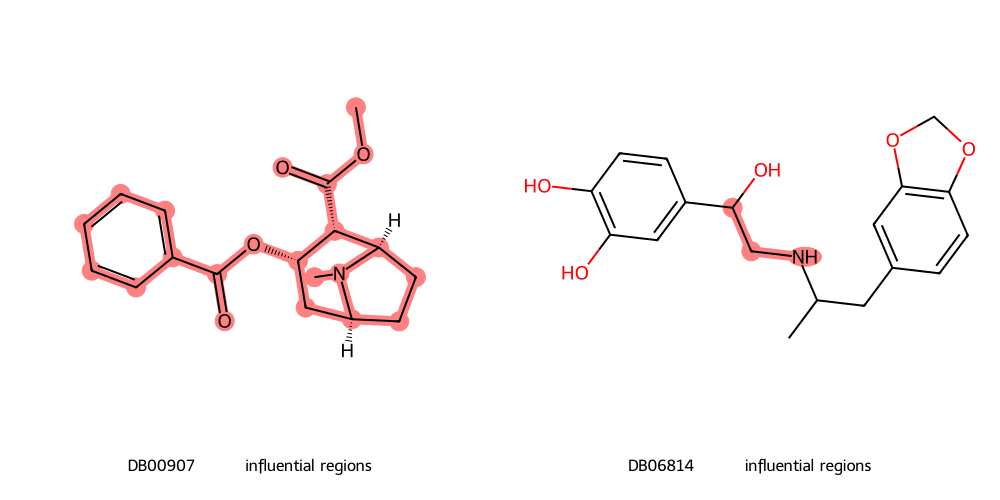

In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw

# Select top 5 influential fingerprint bits
top_bits = []

for bit in top_indices:
    if len(top_bits) >= 5:
        break

    if abs(combined_fp[bit]) < 0.1:
        continue

    _, env_a = get_bit_info(smiles_a, bit)
    _, env_b = get_bit_info(smiles_b, bit)

    if env_a or env_b:
        top_bits.append(bit)


def get_highlight_atoms(smiles, bits):
    mol = Chem.MolFromSmiles(smiles)
    atoms = set()

    for bit in bits:
        _, environments = get_bit_info(smiles, bit)

        for atom_idx, radius in environments:
            atoms.add(atom_idx)

            if radius > 0:
                bond_ids = Chem.FindAtomEnvironmentOfRadiusN(
                    mol, radius, atom_idx
                )

                for bond_idx in bond_ids:
                    bond = mol.GetBondWithIdx(bond_idx)
                    atoms.add(bond.GetBeginAtomIdx())
                    atoms.add(bond.GetEndAtomIdx())

    return mol, sorted(atoms)


mol_a, highlight_a = get_highlight_atoms(smiles_a, top_bits)
mol_b, highlight_b = get_highlight_atoms(smiles_b, top_bits)

print("Selected influential bits:", top_bits)
print("Drug A highlighted atoms:", highlight_a)
print("Drug B highlighted atoms:", highlight_b)

img = Draw.MolsToGridImage(
    [mol_a, mol_b],
    molsPerRow=2,
    subImgSize=(500, 500),
    legends=[
        f"{drug_a} — influential regions",
        f"{drug_b} — influential regions"
    ],
    highlightAtomLists=[
        highlight_a,
        highlight_b
    ]
)

display(img)

In [ ]:
print(f"Prediction: {'INTERACTION' if probability >= 0.5 else 'NO INTERACTION'}")
print(f"Probability: {probability:.4f}\n")

print("Top influential molecular features")
print("-" * 75)

for rank, bit in enumerate(top_bits, 1):
    value = combined_fp[bit]

    if value > 0:
        effect = "SUPPORTS interaction"
    else:
        effect = "OPPOSES interaction"

    _, env_a = get_bit_info(smiles_a, bit)
    _, env_b = get_bit_info(smiles_b, bit)

    print(f"{rank}. Morgan bit {bit}")
    print(f"   Attribution : {value:+.4f}")
    print(f"   Effect      : {effect}")
    print(f"   {drug_a}   : {env_a if env_a else 'not present'}")
    print(f"   {drug_b}   : {env_b if env_b else 'not present'}")
    print()

Prediction: INTERACTION
Probability: 1.0000

Top influential molecular features
---------------------------------------------------------------------------
1. Morgan bit 165
   Attribution : +0.9583
   Effect      : SUPPORTS interaction
   DB00907   : ((16, 2),)
   DB06814   : not present

2. Morgan bit 94
   Attribution : +0.7657
   Effect      : SUPPORTS interaction
   DB00907   : ((10, 2),)
   DB06814   : ((13, 1),)

3. Morgan bit 169
   Attribution : +0.6811
   Effect      : SUPPORTS interaction
   DB00907   : ((3, 2),)
   DB06814   : not present

4. Morgan bit 64
   Attribution : +0.6449
   Effect      : SUPPORTS interaction
   DB00907   : ((12, 1), (13, 1), (14, 1))
   DB06814   : not present

5. Morgan bit 118
   Attribution : -0.6104
   Effect      : OPPOSES interaction
   DB00907   : ((0, 1),)
   DB06814   : not present



[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator
[15:47:11] DEPRECATION WARNING: please use MorganGenerator


In [ ]:
print("=" * 70)
print("EXPLAINABLE DDI PREDICTION")
print("=" * 70)

print(f"\nDrug A       : {drug_a}")
print(f"Drug B       : {drug_b}")
print(f"Prediction   : {'INTERACTION' if probability >= 0.5 else 'NO INTERACTION'}")
print(f"Probability  : {probability:.4f}")

print("\n1. MODEL REPRESENTATION IMPORTANCE")
print("-" * 50)

total_a = np.abs(attr_a).sum()
total_b = np.abs(attr_b).sum()

print(f"Drug A:")
print(f"  Graph embedding       : {np.abs(attr_a[:96]).sum():.4f}")
print(f"  Molecular fingerprint : {np.abs(attr_a[96:352]).sum():.4f}")
print(f"  Molecular descriptors  : {np.abs(attr_a[352:]).sum():.4f}")

print(f"\nDrug B:")
print(f"  Graph embedding       : {np.abs(attr_b[:96]).sum():.4f}")
print(f"  Molecular fingerprint : {np.abs(attr_b[96:352]).sum():.4f}")
print(f"  Molecular descriptors  : {np.abs(attr_b[352:]).sum():.4f}")

print("\n2. MOST INFLUENTIAL MOLECULAR FEATURES")
print("-" * 50)

for rank, bit in enumerate(top_bits, 1):
    value = combined_fp[bit]
    effect = "supports" if value > 0 else "opposes"

    print(
        f"{rank}. Morgan bit {bit}: "
        f"{value:+.4f} ({effect} interaction)"
    )

print("\n3. INTERPRETATION")
print("-" * 50)

print(
    "The model predicts a strong interaction based on learned "
    "graph-level and molecular-level representations."
)
print(
    "The attribution values indicate which learned features "
    "push the prediction toward or away from an interaction."
)
print(
    "These attributions explain the model's decision and should "
    "not be interpreted as direct proof of a biological mechanism."
)

EXPLAINABLE DDI PREDICTION

Drug A       : DB00907
Drug B       : DB06814
Prediction   : INTERACTION
Probability  : 1.0000

1. MODEL REPRESENTATION IMPORTANCE
--------------------------------------------------
Drug A:
  Graph embedding       : 24.6194
  Molecular fingerprint : 14.4220
  Molecular descriptors  : 0.9828

Drug B:
  Graph embedding       : 21.0789
  Molecular fingerprint : 10.2018
  Molecular descriptors  : 5.0480

2. MOST INFLUENTIAL MOLECULAR FEATURES
--------------------------------------------------
1. Morgan bit 165: +0.9583 (supports interaction)
2. Morgan bit 94: +0.7657 (supports interaction)
3. Morgan bit 169: +0.6811 (supports interaction)
4. Morgan bit 64: +0.6449 (supports interaction)
5. Morgan bit 118: -0.6104 (opposes interaction)

3. INTERPRETATION
--------------------------------------------------
The model predicts a strong interaction based on learned graph-level and molecular-level representations.
The attribution values indicate which learned features 

In [ ]:
def predict_ddi(drug_a, drug_b):
    if drug_a not in drug_to_idx:
        raise ValueError(f"{drug_a} not found in graph_drugs")

    if drug_b not in drug_to_idx:
        raise ValueError(f"{drug_b} not found in graph_drugs")

    idx_a = drug_to_idx[drug_a]
    idx_b = drug_to_idx[drug_b]

    rep_a = torch.tensor(
        drug_repr[idx_a],
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    rep_b = torch.tensor(
        drug_repr[idx_b],
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    model_pair.eval()

    with torch.no_grad():
        logit = model_pair(rep_a, rep_b)
        probability = torch.sigmoid(logit).item()

    prediction = "INTERACTION" if probability >= 0.5 else "NO INTERACTION"

    print("=" * 60)
    print("DDI PREDICTION")
    print("=" * 60)
    print(f"Drug A      : {drug_a}")
    print(f"Drug B      : {drug_b}")
    print(f"Prediction  : {prediction}")
    print(f"Probability : {probability:.4f}")
    print("=" * 60)

    return prediction, probability

In [ ]:
prediction, probability = predict_ddi("DB00907", "DB06814")

DDI PREDICTION
Drug A      : DB00907
Drug B      : DB06814
Prediction  : INTERACTION
Probability : 1.0000


In [ ]:
def explain_ddi(drug_a, drug_b):
    # -----------------------------
    # 1. Validate drugs
    # -----------------------------
    if drug_a not in drug_to_idx:
        raise ValueError(f"{drug_a} not found in graph_drugs")

    if drug_b not in drug_to_idx:
        raise ValueError(f"{drug_b} not found in graph_drugs")

    idx_a = drug_to_idx[drug_a]
    idx_b = drug_to_idx[drug_b]

    # -----------------------------
    # 2. Prepare representations
    # -----------------------------
    rep_a = torch.tensor(
        drug_repr[idx_a],
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    rep_b = torch.tensor(
        drug_repr[idx_b],
        dtype=torch.float32,
        device=device
    ).unsqueeze(0)

    rep_a.requires_grad_(True)
    rep_b.requires_grad_(True)

    model_pair.eval()
    model_pair.zero_grad()

    # -----------------------------
    # 3. Prediction
    # -----------------------------
    logit = model_pair(rep_a, rep_b)
    probability = torch.sigmoid(logit).item()

    prediction = (
        "INTERACTION"
        if probability >= 0.5
        else "NO INTERACTION"
    )

    # -----------------------------
    # 4. Gradient attribution
    # -----------------------------
    logit.backward()

    grad_a = rep_a.grad.detach().cpu().numpy()[0]
    grad_b = rep_b.grad.detach().cpu().numpy()[0]

    values_a = rep_a.detach().cpu().numpy()[0]
    values_b = rep_b.detach().cpu().numpy()[0]

    attr_a = grad_a * values_a
    attr_b = grad_b * values_b

    # -----------------------------
    # 5. Representation importance
    # -----------------------------
    graph_a = np.abs(attr_a[:96]).sum()
    fp_a = np.abs(attr_a[96:352]).sum()
    desc_a = np.abs(attr_a[352:]).sum()

    graph_b = np.abs(attr_b[:96]).sum()
    fp_b = np.abs(attr_b[96:352]).sum()
    desc_b = np.abs(attr_b[352:]).sum()

    # -----------------------------
    # 6. Morgan fingerprint bits
    # -----------------------------
    combined_fp = (
        attr_a[96:352] +
        attr_b[96:352]
    )

    ranked_bits = np.argsort(
        np.abs(combined_fp)
    )[::-1]

    top_bits = []

    for bit in ranked_bits:
        if len(top_bits) >= 5:
            break

        if abs(combined_fp[bit]) < 0.1:
            continue

        top_bits.append(int(bit))

    # -----------------------------
    # 7. Print explanation
    # -----------------------------
    print("=" * 70)
    print("EXPLAINABLE DDI PREDICTION")
    print("=" * 70)

    print(f"\nDrug A       : {drug_a}")
    print(f"Drug B       : {drug_b}")
    print(f"Prediction   : {prediction}")
    print(f"Probability  : {probability:.4f}")

    print("\nREPRESENTATION IMPORTANCE")
    print("-" * 50)

    print(f"\n{drug_a}")
    print(f"  Graph embedding       : {graph_a:.4f}")
    print(f"  Molecular fingerprint : {fp_a:.4f}")
    print(f"  Molecular descriptors : {desc_a:.4f}")

    print(f"\n{drug_b}")
    print(f"  Graph embedding       : {graph_b:.4f}")
    print(f"  Molecular fingerprint : {fp_b:.4f}")
    print(f"  Molecular descriptors : {desc_b:.4f}")

    print("\nTOP INFLUENTIAL MORGAN FEATURES")
    print("-" * 50)

    for rank, bit in enumerate(top_bits, 1):
        value = combined_fp[bit]
        effect = (
            "SUPPORTS interaction"
            if value > 0
            else "OPPOSES interaction"
        )

        print(
            f"{rank}. Bit {bit}: "
            f"{value:+.4f} ({effect})"
        )

    print("\n" + "=" * 70)

    return {
        "drug_a": drug_a,
        "drug_b": drug_b,
        "prediction": prediction,
        "probability": probability,
        "graph_importance_a": graph_a,
        "fingerprint_importance_a": fp_a,
        "descriptor_importance_a": desc_a,
        "graph_importance_b": graph_b,
        "fingerprint_importance_b": fp_b,
        "descriptor_importance_b": desc_b,
        "top_morgan_bits": top_bits
    }

In [ ]:
explanation = explain_ddi("DB00907", "DB06814")

EXPLAINABLE DDI PREDICTION

Drug A       : DB00907
Drug B       : DB06814
Prediction   : INTERACTION
Probability  : 1.0000

REPRESENTATION IMPORTANCE
--------------------------------------------------

DB00907
  Graph embedding       : 24.6194
  Molecular fingerprint : 14.4220
  Molecular descriptors : 0.9828

DB06814
  Graph embedding       : 21.0789
  Molecular fingerprint : 10.2018
  Molecular descriptors : 5.0480

TOP INFLUENTIAL MORGAN FEATURES
--------------------------------------------------
1. Bit 165: +0.9583 (SUPPORTS interaction)
2. Bit 94: +0.7657 (SUPPORTS interaction)
3. Bit 169: +0.6811 (SUPPORTS interaction)
4. Bit 64: +0.6449 (SUPPORTS interaction)
5. Bit 118: -0.6104 (OPPOSES interaction)



In [ ]:
explain_ddi("DB00907", "DB06814")

EXPLAINABLE DDI PREDICTION

Drug A       : DB00907
Drug B       : DB06814
Prediction   : INTERACTION
Probability  : 1.0000

REPRESENTATION IMPORTANCE
--------------------------------------------------

DB00907
  Graph embedding       : 24.6194
  Molecular fingerprint : 14.4220
  Molecular descriptors : 0.9828

DB06814
  Graph embedding       : 21.0789
  Molecular fingerprint : 10.2018
  Molecular descriptors : 5.0480

TOP INFLUENTIAL MORGAN FEATURES
--------------------------------------------------
1. Bit 165: +0.9583 (SUPPORTS interaction)
2. Bit 94: +0.7657 (SUPPORTS interaction)
3. Bit 169: +0.6811 (SUPPORTS interaction)
4. Bit 64: +0.6449 (SUPPORTS interaction)
5. Bit 118: -0.6104 (OPPOSES interaction)



{'drug_a': 'DB00907',
 'drug_b': 'DB06814',
 'prediction': 'INTERACTION',
 'probability': 0.9999979734420776,
 'graph_importance_a': np.float32(24.6194),
 'fingerprint_importance_a': np.float32(14.421974),
 'descriptor_importance_a': np.float32(0.9827925),
 'graph_importance_b': np.float32(21.078888),
 'fingerprint_importance_b': np.float32(10.201839),
 'descriptor_importance_b': np.float32(5.0479693),
 'top_morgan_bits': [165, 94, 169, 64, 118]}

In [ ]:
import random

drug_a, drug_b = random.sample(list(graph_drugs), 2)

print(f"Testing pair: {drug_a} + {drug_b}\n")

explanation = explain_ddi(drug_a, drug_b)

Testing pair: DB12131 + DB13792

EXPLAINABLE DDI PREDICTION

Drug A       : DB12131
Drug B       : DB13792
Prediction   : NO INTERACTION
Probability  : 0.4213

REPRESENTATION IMPORTANCE
--------------------------------------------------

DB12131
  Graph embedding       : 22.1200
  Molecular fingerprint : 16.7938
  Molecular descriptors : 1.7267

DB13792
  Graph embedding       : 29.4513
  Molecular fingerprint : 12.0343
  Molecular descriptors : 4.4437

TOP INFLUENTIAL MORGAN FEATURES
--------------------------------------------------
1. Bit 83: +1.4788 (SUPPORTS interaction)
2. Bit 71: +1.1305 (SUPPORTS interaction)
3. Bit 115: +1.0110 (SUPPORTS interaction)
4. Bit 222: +0.9506 (SUPPORTS interaction)
5. Bit 36: +0.8561 (SUPPORTS interaction)



In [ ]:
# Pick a known positive pair from the test set
positive_pair = test_df[test_df["label"] == 1].iloc[0]

drug_a = positive_pair["drug_a"]
drug_b = positive_pair["drug_b"]

print(f"Known test-set positive pair: {drug_a} + {drug_b}\n")

explanation = explain_ddi(drug_a, drug_b)

Known test-set positive pair: DB00624 + DB01222

EXPLAINABLE DDI PREDICTION

Drug A       : DB00624
Drug B       : DB01222
Prediction   : INTERACTION
Probability  : 1.0000

REPRESENTATION IMPORTANCE
--------------------------------------------------

DB00624
  Graph embedding       : 42.0992
  Molecular fingerprint : 22.0197
  Molecular descriptors : 4.6782

DB01222
  Graph embedding       : 16.3218
  Molecular fingerprint : 11.5240
  Molecular descriptors : 2.7782

TOP INFLUENTIAL MORGAN FEATURES
--------------------------------------------------
1. Bit 50: -1.8067 (OPPOSES interaction)
2. Bit 242: +1.6952 (SUPPORTS interaction)
3. Bit 182: -1.5698 (OPPOSES interaction)
4. Bit 119: +1.4820 (SUPPORTS interaction)
5. Bit 81: +1.2670 (SUPPORTS interaction)



In [ ]:
# Find a known negative test pair where BOTH drugs are in the graph
valid_negative = test_df[
    (test_df["label"] == 0) &
    (test_df["drug_a"].isin(graph_drugs)) &
    (test_df["drug_b"].isin(graph_drugs))
].iloc[0]

drug_a = valid_negative["drug_a"]
drug_b = valid_negative["drug_b"]

print(f"Known test-set negative pair: {drug_a} + {drug_b}")
print("Drug A graph coverage: YES")
print("Drug B graph coverage: YES\n")

explanation = explain_ddi(drug_a, drug_b)

Known test-set negative pair: DB01128 + DB05016
Drug A graph coverage: YES
Drug B graph coverage: YES

EXPLAINABLE DDI PREDICTION

Drug A       : DB01128
Drug B       : DB05016
Prediction   : NO INTERACTION
Probability  : 0.0083

REPRESENTATION IMPORTANCE
--------------------------------------------------

DB01128
  Graph embedding       : 15.4553
  Molecular fingerprint : 7.5688
  Molecular descriptors : 2.8098

DB05016
  Graph embedding       : 7.8692
  Molecular fingerprint : 1.9620
  Molecular descriptors : 2.7536

TOP INFLUENTIAL MORGAN FEATURES
--------------------------------------------------
1. Bit 24: -0.5883 (OPPOSES interaction)
2. Bit 105: -0.5684 (OPPOSES interaction)
3. Bit 116: +0.4421 (SUPPORTS interaction)
4. Bit 81: +0.3560 (SUPPORTS interaction)
5. Bit 162: +0.3103 (SUPPORTS interaction)



In [ ]:
test_drugs = set(test_df["drug_a"]) | set(test_df["drug_b"])
missing = test_drugs - set(drug_to_idx)

print("Test pairs:", len(test_df))
print("Test drugs missing graph embeddings:", len(missing))

Test pairs: 266820
Test drugs missing graph embeddings: 7769


In [ ]:
# Check graph coverage of the complete test set

test_df = test_df.copy()

test_df["drug_a_covered"] = test_df["drug_a"].isin(drug_to_idx)
test_df["drug_b_covered"] = test_df["drug_b"].isin(drug_to_idx)

both_covered = test_df["drug_a_covered"] & test_df["drug_b_covered"]
one_covered = test_df["drug_a_covered"] ^ test_df["drug_b_covered"]
neither_covered = ~test_df["drug_a_covered"] & ~test_df["drug_b_covered"]

print("Total test pairs:", len(test_df))
print("Both drugs covered:", int(both_covered.sum()))
print("Exactly one drug missing:", int(one_covered.sum()))
print("Both drugs missing:", int(neither_covered.sum()))
print("Test-pair coverage:", round(both_covered.mean() * 100, 3), "%")

print("\nCoverage by label:")
print(
    test_df.assign(
        coverage=[
            "Both covered" if a and b else
            "One missing" if a or b else
            "Neither covered"
            for a, b in zip(
                test_df["drug_a_covered"],
                test_df["drug_b_covered"]
            )
        ]
    ).groupby(["label", "coverage"]).size()
)

Total test pairs: 266820
Both drugs covered: 145006
Exactly one drug missing: 59052
Both drugs missing: 62762
Test-pair coverage: 54.346 %

Coverage by label:
label  coverage       
0      Both covered        11613
       Neither covered     62762
       One missing         59035
1      Both covered       133393
       One missing            17
dtype: int64


In [ ]:
# Inspect graph coverage by label and missing-drug frequency

for label in [0, 1]:
    subset = test_df[test_df["label"] == label]

    missing_a = ~subset["drug_a"].isin(drug_to_idx)
    missing_b = ~subset["drug_b"].isin(drug_to_idx)

    print(f"\nLabel {label}:")
    print("Total pairs:", len(subset))
    print("Drug A missing:", int(missing_a.sum()))
    print("Drug B missing:", int(missing_b.sum()))
    print(
        "At least one missing:",
        int((missing_a | missing_b).sum())
    )

print("\nMost frequent missing drugs in test pairs:")
missing_pairs = test_df[
    ~test_df["drug_a"].isin(drug_to_idx)
    | ~test_df["drug_b"].isin(drug_to_idx)
]

missing_counts = pd.concat([
    missing_pairs.loc[
        ~missing_pairs["drug_a"].isin(drug_to_idx), "drug_a"
    ],
    missing_pairs.loc[
        ~missing_pairs["drug_b"].isin(drug_to_idx), "drug_b"
    ]
]).value_counts()

print(missing_counts.head(15))


Label 0:
Total pairs: 133410
Drug A missing: 89303
Drug B missing: 95256
At least one missing: 121797

Label 1:
Total pairs: 133410
Drug A missing: 5
Drug B missing: 12
At least one missing: 17

Most frequent missing drugs in test pairs:
DB00632    42
DB12517    42
DB03982    41
DB14944    41
DB04366    41
DB02889    41
DB07237    40
DB15367    40
DB13330    40
DB05966    39
DB12818    39
DB01706    39
DB04982    39
DB08529    39
DB07394    39
Name: count, dtype: int64


In [ ]:
# Diagnose graph coverage across all splits and the original dataset

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    a_covered = df["drug_a"].isin(drug_to_idx)
    b_covered = df["drug_b"].isin(drug_to_idx)

    print(f"\n{name}:")
    print("Total pairs:", len(df))
    print("Both drugs covered:", int((a_covered & b_covered).sum()))
    print("At least one drug missing:", int((~(a_covered & b_covered)).sum()))
    print("Positive pairs:", int((df["label"] == 1).sum()))
    print("Negative pairs:", int((df["label"] == 0).sum()))

print("\nGraph drugs:", len(drug_to_idx))
print("Unique drugs in training:", len(set(train_df["drug_a"]) | set(train_df["drug_b"])))
print("Unique drugs in validation:", len(set(val_df["drug_a"]) | set(val_df["drug_b"])))
print("Unique drugs in test:", len(set(test_df["drug_a"]) | set(test_df["drug_b"])))


Train:
Total pairs: 2134560
Both drugs covered: 1159224
At least one drug missing: 975336
Positive pairs: 1067280
Negative pairs: 1067280

Validation:
Total pairs: 266820
Both drugs covered: 144798
At least one drug missing: 122022
Positive pairs: 133410
Negative pairs: 133410

Test:
Total pairs: 266820
Both drugs covered: 145006
At least one drug missing: 121814
Positive pairs: 133410
Negative pairs: 133410

Graph drugs: 4250
Unique drugs in training: 12018
Unique drugs in validation: 11995
Unique drugs in test: 11996


In [ ]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix

model_pair.eval()

a_idx, b_idx, valid = map_graph_pairs(test_df)
valid_idx = np.flatnonzero(valid)

y_true = test_df["label"].to_numpy()[valid_idx]
y_prob = []

with torch.no_grad():
    for start in range(0, len(valid_idx), 8192):
        idx = valid_idx[start:start + 8192]

        X_a = torch.tensor(
            drug_repr[a_idx[idx]], dtype=torch.float32, device=device
        )
        X_b = torch.tensor(
            drug_repr[b_idx[idx]], dtype=torch.float32, device=device
        )

        logits = model_pair(X_a, X_b)
        y_prob.extend(torch.sigmoid(logits).cpu().numpy())

y_prob = np.asarray(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

print(f"Test pairs evaluated: {len(valid_idx):,}/{len(test_df):,}")
print(f"Test coverage: {100 * len(valid_idx) / len(test_df):.2f}%")
print(f"Accuracy (covered pairs): {accuracy_score(y_true, y_pred):.5f}")
print(f"ROC-AUC (covered pairs):  {roc_auc_score(y_true, y_prob):.5f}")
print("\nClassification Report:")
print(classification_report(y_true, y_pred, digits=5))
print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Test pairs evaluated: 145,006/266,820
Test coverage: 54.35%
Accuracy (covered pairs): 0.98976
ROC-AUC (covered pairs):  0.99606

Classification Report:
              precision    recall  f1-score   support

           0    0.97900   0.89124   0.93306     11613
           1    0.99061   0.99834   0.99446    133393

    accuracy                        0.98976    145006
   macro avg    0.98480   0.94479   0.96376    145006
weighted avg    0.98968   0.98976   0.98954    145006

Confusion Matrix:
[[ 10350   1263]
 [   222 133171]]


In [ ]:
# ============================================================
# SAVE COMPLETE DDI CHECKPOINT TO GOOGLE DRIVE
# Run this after the model and explanation cells have completed.
# ============================================================

import os
import json
import pickle
import shutil
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from datetime import datetime

SAVE_DIR = Path(
    "/content/drive/MyDrive/Explainable_DDI/checkpoint_bundle"
)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

saved_files = []

def save_numpy(name, array):
    path = SAVE_DIR / f"{name}.npy"
    np.save(path, np.asarray(array), allow_pickle=False)
    saved_files.append(path.name)
    print(f"Saved {path.name} — {path.stat().st_size / 1024**2:.2f} MB")

def save_pickle(name, obj):
    path = SAVE_DIR / f"{name}.pkl"
    with open(path, "wb") as f:
        pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)
    saved_files.append(path.name)
    print(f"Saved {path.name} — {path.stat().st_size / 1024**2:.2f} MB")

# 1. Save trained neural network and best checkpoint
if "model_pair" in globals():
    model_checkpoint = {
        "model_state_dict": {
            k: v.detach().cpu()
            for k, v in model_pair.state_dict().items()
        },
        "best_model_state_dict": (
            best_pair_state if "best_pair_state" in globals() else None
        ),
        "input_dim": 358,
        "encoder_dims": [358, 192, 96],
        "classifier_dims": [288, 192, 64, 1],
        "threshold": 0.50,
        "seed": 42,
        "saved_at": datetime.now().isoformat()
    }

    path = SAVE_DIR / "ddi_neural_checkpoint.pt"
    torch.save(model_checkpoint, path)
    saved_files.append(path.name)
    print(f"\nSaved neural checkpoint — {path.stat().st_size / 1024**2:.2f} MB")
else:
    print("WARNING: model_pair not found; neural checkpoint not saved.")

# 2. Save the final drug representations and graph/molecular inputs
for variable_name, filename in [
    ("drug_repr", "drug_representations"),
    ("graph_embeddings", "graph_embeddings"),
    ("molecular_features", "molecular_features"),
    ("degree", "graph_degrees"),
    ("edge_a", "graph_edge_a"),
    ("edge_b", "graph_edge_b"),
]:
    if variable_name in globals():
        save_numpy(filename, globals()[variable_name])

# 3. Save DrugBank ID mapping and graph vocabulary
for variable_name, filename in [
    ("graph_drugs", "graph_drugs"),
    ("drug_to_idx", "drug_to_idx"),
    ("smiles_map", "smiles_map"),
]:
    if variable_name in globals():
        save_pickle(filename, globals()[variable_name])

# 4. Save Word2Vec model for reproducible graph embeddings
if "graph_w2v" in globals():
    path = SAVE_DIR / "graph_word2vec.model"
    graph_w2v.save(str(path))
    saved_files.append(path.name)
    print(f"Saved {path.name}")

# 5. Save exact current train/validation/test pair splits
# These preserve the rows used by this notebook.
for variable_name in ["train_df", "val_df", "test_df"]:
    if variable_name in globals():
        path = SAVE_DIR / f"{variable_name}.csv"
        globals()[variable_name].to_csv(path, index=False)
        saved_files.append(path.name)
        print(f"Saved {path.name} — {path.stat().st_size / 1024**2:.2f} MB")

# 6. Save evaluation metrics currently available
metrics = {
    "seed": 42,
    "model": "PairwiseDDI",
    "input_dimensions": {
        "graph_embedding": 96,
        "morgan_fingerprint": 256,
        "molecular_descriptors": 6,
        "total": 358
    },
    "threshold": 0.50
}

for name in [
    "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc",
    "best_pair_auc"
]:
    if name in globals():
        value = globals()[name]
        if isinstance(value, (int, float, np.number)):
            metrics[name] = float(value)

metrics_path = SAVE_DIR / "metrics.json"
with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=2)
saved_files.append(metrics_path.name)

# 7. Save a manifest so we can check the bundle after reconnecting
manifest = {
    "saved_at": datetime.now().isoformat(),
    "files": saved_files,
    "notes": [
        "Model input: 358-dimensional drug representations.",
        "Threshold saved as 0.50.",
        "Validation metrics are not test metrics.",
        "Save the Colab notebook separately to Google Drive as well."
    ]
}

with open(SAVE_DIR / "manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("\n" + "=" * 60)
print("CHECKPOINT BUNDLE SAVED")
print("=" * 60)
print("Location:", SAVE_DIR)
print("Files saved:", len(saved_files) + 1)
print("Total size:", round(
    sum(p.stat().st_size for p in SAVE_DIR.iterdir() if p.is_file()) / 1024**2,
    2
), "MB")
print("\nImportant: also save the notebook itself using")
print("File → Save a copy in Drive.")
print("After reconnecting, verify that manifest.json exists.")


Saved neural checkpoint — 1.22 MB
Saved drug_representations.npy — 5.80 MB
Saved graph_embeddings.npy — 1.56 MB
Saved molecular_features.npy — 4.25 MB
Saved graph_degrees.npy — 0.03 MB
Saved graph_edge_a.npy — 4.07 MB
Saved graph_edge_b.npy — 4.07 MB
Saved graph_drugs.pkl — 0.04 MB
Saved drug_to_idx.pkl — 0.05 MB
Saved smiles_map.pkl — 0.78 MB
Saved graph_word2vec.model
Saved train_df.csv — 36.64 MB
Saved val_df.csv — 4.58 MB
Saved test_df.csv — 7.30 MB

CHECKPOINT BUNDLE SAVED
Location: /content/drive/MyDrive/Explainable_DDI/checkpoint_bundle
Files saved: 16
Total size: 73.63 MB

Important: also save the notebook itself using
File → Save a copy in Drive.
After reconnecting, verify that manifest.json exists.
